# Mental Health Text Classification

## This notebook explores Mental Health Text Classification Dataset (4-class) from Hugging Face

## This project is for educational and research purposes


In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

print("Successfully Imported")

Successfully Imported


In [2]:
BASE_URL = (
    "https://huggingface.co/datasets/"
    "ourafla/Mental-Health_Text-Classification_Dataset/resolve/main/"
)

TRAIN_FILE = "mental_heath_unbanlanced.csv"
TEST_FILE = "mental_health_combined_test.csv"

train_url = BASE_URL + TRAIN_FILE
test_url = BASE_URL + TEST_FILE

print("Dataset URLs created.")

Dataset URLs created.


In [3]:
pd.set_option("display.max_colwidth", 200)

train_df = pd.read_csv(train_url)
test_df = pd.read_csv(test_url)

print("Training dataset loaded.")
print("Test dataset loaded.")

Training dataset loaded.
Test dataset loaded.


In [4]:
print("Training shape:", train_df.shape)
print("Test shape:", test_df.shape)

Training shape: (49612, 3)
Test shape: (992, 2)


In [5]:
print("Training columns:")
print(train_df.columns.tolist())

print("\nTest columns:")
print(test_df.columns.tolist())

Training columns:
['Unique_ID', 'text', 'status']

Test columns:
['text', 'status']


In [6]:
train_df.head()

,Unique_ID,text,status
0,0.0,oh my gosh,Anxiety
1,1.0,"trouble sleeping, confused mind, restless heart. All out of tune",Anxiety
2,2.0,"All wrong, back off dear, forward doubt. Stay in a restless and restless place",Anxiety
3,3.0,I've shifted my focus to something else but I'm still worried,Anxiety
4,4.0,"I'm restless and restless, it's been a month now, boy. What do you mean?",Anxiety


In [7]:
test_df.head()

,text,status
0,i don't understand whats wrong with me. i don't know why i freak out sometimes. like right now i'm just laying in bed nothing is happening but i can't keep the tears running from down my face. it'...,Anxiety
1,"usually when i have anxiety just chatting with someone or just having someone to physically be there for me is all i need to start feeling better. my anxiety is always worst at night, and it’s suc...",Anxiety
2,"well, i've had anxiety and panic syndrome for a few years. it all started in my school back in 2014, my heart went insane for no reason, got so bad that i had to ask my dad to pick me up, we went ...",Anxiety
3,"for the most minimal of things, like standing in someone's way for just a moment. does anyone else notice this character trait? it's not out of habit, it's a subconscious quirk. i think, deep down...",Anxiety
4,i stay away from family and live with my roommate who literally games all the fuckin time! it's like he is happy he doesn't have to go to college anymore this is a blessing for him. he has no othe...,Anxiety


In [8]:
train_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 49612 entries, 0 to 49611
Data columns (total 3 columns):
 #   Column     Non-Null Count  Dtype  
---  ------     --------------  -----  
 0   Unique_ID  40012 non-null  float64
 1   text       49612 non-null  object 
 2   status     49612 non-null  object 
dtypes: float64(1), object(2)
memory usage: 1.1+ MB


In [9]:
test_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 992 entries, 0 to 991
Data columns (total 2 columns):
 #   Column  Non-Null Count  Dtype 
---  ------  --------------  ----- 
 0   text    992 non-null    object
 1   status  992 non-null    object
dtypes: object(2)
memory usage: 15.6+ KB


In [10]:
print("Missing values in training data:")
print(train_df.isnull().sum())

print("\nMissing values in test data:")
print(test_df.isnull().sum())

Missing values in training data:
Unique_ID    9600
text            0
status          0
dtype: int64

Missing values in test data:
text      0
status    0
dtype: int64


In [11]:
print("Training categories:")
print(train_df["status"].unique())

Training categories:
['Anxiety' 'Normal' 'Depression' 'Suicidal']


In [12]:
print("Number of categories:", train_df["status"].nunique())

Number of categories: 4


In [13]:
print(train_df["status"].value_counts())

status
Normal        18391
Depression    14506
Suicidal      11212
Anxiety        5503
Name: count, dtype: int64


In [23]:
print("=== DATASET OVERVIEW ===")

print(f"Shape: {train_df.shape}")

print("\nColumns:")
print(train_df.columns.tolist())

print("\nClass Distribution:")
print(train_df["status"].value_counts())

print("\nRandom Sample:")
display(train_df[["text", "status"]].sample(8, random_state=42))

=== DATASET OVERVIEW ===
Shape: (49612, 4)

Columns:
['Unique_ID', 'text', 'status', 'text_length']

Class Distribution:
status
Normal        18391
Depression    14506
Suicidal      11212
Anxiety        5503
Name: count, dtype: int64

Random Sample:


,text,status
29854,"@slydevil damn right!, kinda hate myself for not having the system to lay it on... being poor sucks",Suicidal
39688,How do you manage anxiety when sleep deprived? I am eating some good I haven't eaten for hours. I had a headache ive gotten like 2 hours sleep the past couple of nights. I walked out in the cold f...,Anxiety
3502,3alam had 48,Normal
38848,my bf said i dont try to make it better for myself like i dont hear it enough in my fucking head. i spent so many fucking years beating myself up and hearing it from my parents that i dont fucking...,Depression
30167,"Congratulations, Jim! I'm a great editor, not a great media artist.",Normal
33863,kapag nakakapanood ako ng video about mental health depression etc nattrigger pa rin ako naaalala ko yung mga pinagdaanan ko but still kahit yun yung mga darkest moment ng buhay ko grateful pa rin...,Depression
26158,rained out?,Normal
35106,moony 9 yeah is it bcoz kal penn is a visiting lecturer somewhere n cant be on the show anymore im gon na miss him,Normal


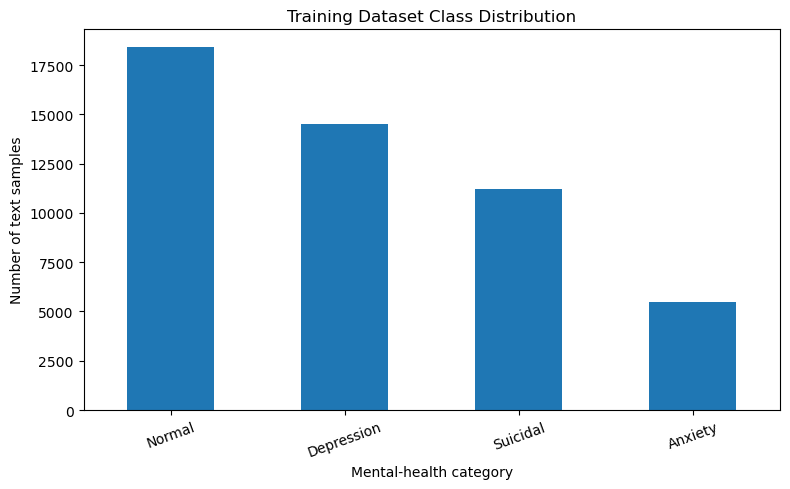

In [15]:
class_counts = train_df["status"].value_counts()

plt.figure(figsize=(8, 5))
class_counts.plot(kind="bar")

plt.title("Training Dataset Class Distribution")
plt.xlabel("Mental-health category")
plt.ylabel("Number of text samples")
plt.xticks(rotation=20)

plt.tight_layout()
plt.show()

In [16]:
test_class_counts = test_df["status"].value_counts()

print(test_class_counts)

status
Anxiety       248
Depression    248
Normal        248
Suicidal      248
Name: count, dtype: int64


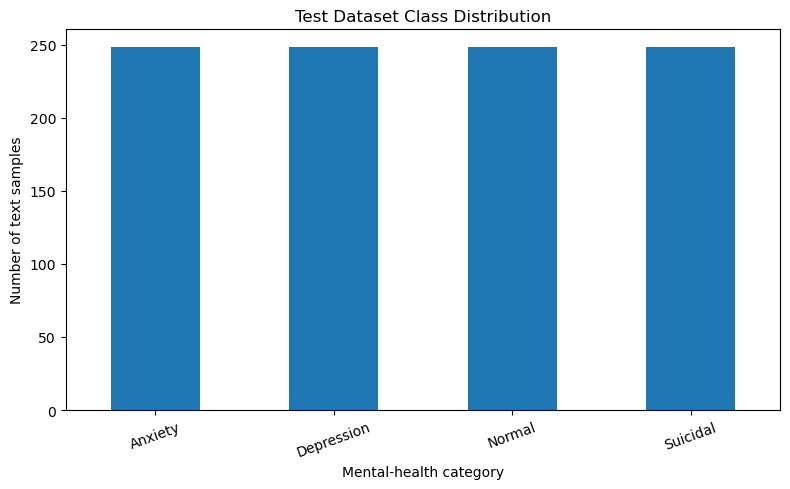

In [17]:
plt.figure(figsize=(8, 5))
test_class_counts.plot(kind="bar")

plt.title("Test Dataset Class Distribution")
plt.xlabel("Mental-health category")
plt.ylabel("Number of text samples")
plt.xticks(rotation=20)

plt.tight_layout()
plt.show()

In [18]:
train_df["text_length"] = train_df["text"].fillna("").astype(str).str.len()

train_df["text_length"].describe()

count    49612.000000
mean       399.227143
std        617.780591
min          7.000000
25%         74.000000
50%        242.000000
75%        559.000000
max      38785.000000
Name: text_length, dtype: float64

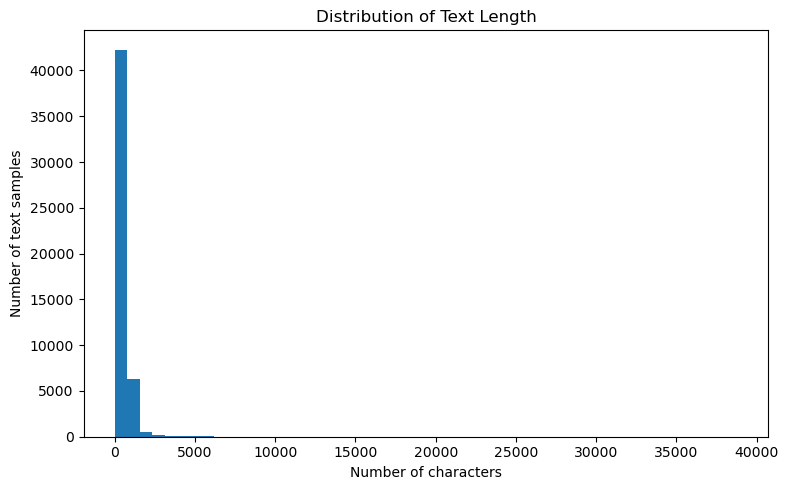

In [19]:
plt.figure(figsize=(8, 5))

plt.hist(train_df["text_length"], bins=50)

plt.title("Distribution of Text Length")
plt.xlabel("Number of characters")
plt.ylabel("Number of text samples")

plt.tight_layout()
plt.show()

In [20]:
train_df.groupby("status")["text_length"].describe()

,count,mean,std,min,25%,50%,75%,max
status,,,,,,,,
Anxiety,5503.0,650.915501,766.305985,10.0,261.5,498.0,825.0,14774.0
Depression,14506.0,535.168137,536.376846,10.0,238.0,437.0,738.0,23386.0
Normal,18391.0,123.547387,384.036074,10.0,31.0,60.0,117.0,38785.0
Suicidal,11212.0,552.012130,763.885587,7.0,188.0,395.0,711.0,38738.0


<Figure size 900x500 with 0 Axes>

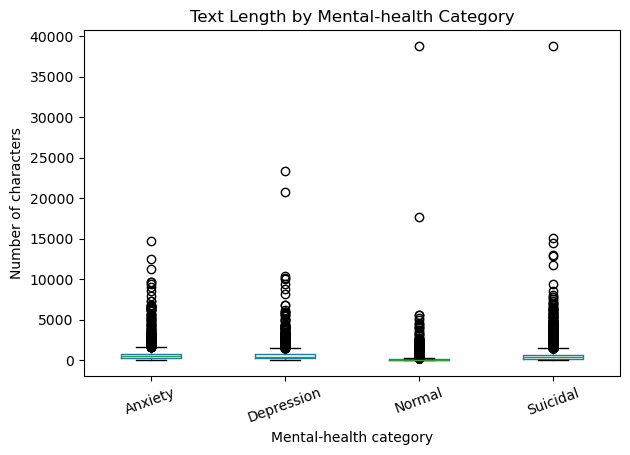

In [21]:
plt.figure(figsize=(9, 5))

train_df.boxplot(
    column="text_length",
    by="status",
    grid=False
)

plt.title("Text Length by Mental-health Category")
plt.suptitle("")
plt.xlabel("Mental-health category")
plt.ylabel("Number of characters")
plt.xticks(rotation=20)

plt.tight_layout()
plt.show()

In [22]:
train_df[["text", "status"]].sample(10, random_state=42)

,text,status
29854,"@slydevil damn right!, kinda hate myself for not having the system to lay it on... being poor sucks",Suicidal
39688,How do you manage anxiety when sleep deprived? I am eating some good I haven't eaten for hours. I had a headache ive gotten like 2 hours sleep the past couple of nights. I walked out in the cold f...,Anxiety
3502,3alam had 48,Normal
38848,my bf said i dont try to make it better for myself like i dont hear it enough in my fucking head. i spent so many fucking years beating myself up and hearing it from my parents that i dont fucking...,Depression
30167,"Congratulations, Jim! I'm a great editor, not a great media artist.",Normal
33863,kapag nakakapanood ako ng video about mental health depression etc nattrigger pa rin ako naaalala ko yung mga pinagdaanan ko but still kahit yun yung mga darkest moment ng buhay ko grateful pa rin...,Depression
26158,rained out?,Normal
35106,moony 9 yeah is it bcoz kal penn is a visiting lecturer somewhere n cant be on the show anymore im gon na miss him,Normal
1406,jungkook yeager trending yuuh,Normal
36393,why is it that anytime that i plan what do i get sick and all the plan go out the window,Normal
